# Workshop 2 - Object detection using web camera
## Name : Sanchita Sandeep
## Register number : 212224240142

In [1]:
!pip install ultralytics opencv-python matplotlib

Defaulting to user installation because normal site-packages is not writeable


In [5]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
from IPython.display import clear_output

In [6]:
# Load a more accurate YOLO model
model = YOLO("yolov8m.pt")

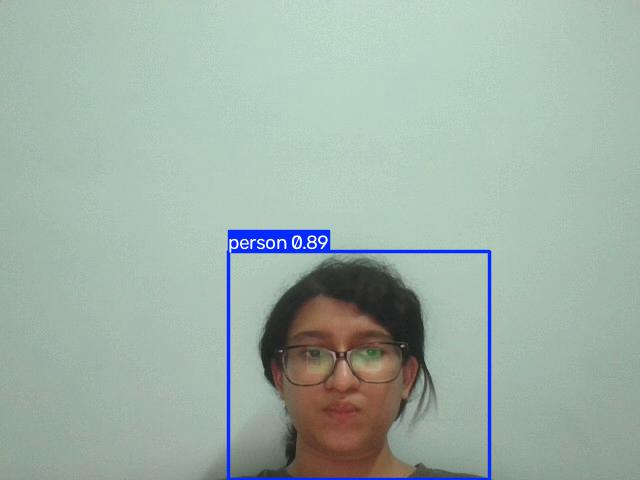

Stopped by user.
Webcam released.


In [2]:
import cv2
from ultralytics import YOLO
from IPython.display import display, clear_output, Image
import PIL.Image
import io

# Load model
model = YOLO("yolov8m.pt")

# Open webcam
cap = cv2.VideoCapture(0, cv2.CAP_DSHOW)

if not cap.isOpened():
    print("Error: Could not open webcam.")
else:
    try:
        print("Streaming... Press the Stop (■) button on the toolbar to end.")
        while cap.isOpened():
            ret, frame = cap.read()
            if not ret:
                print("Failed to capture frame.")
                break 
            
            # Perform object detection
            results = model(frame, conf=0.60, verbose=False)
            annotated_frame = results[0].plot()
            
            # Convert OpenCV BGR to RGB, then to PIL Image
            annotated_frame = cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB)
            img_pil = PIL.Image.fromarray(annotated_frame)
            
            # Encode to JPEG bytes to display smoothly in Jupyter
            f = io.BytesIO()
            img_pil.save(f, format="JPEG")
            
            # Clear output and display the new frame instantly
            clear_output(wait=True)
            display(Image(data=f.getvalue()))
            
    except KeyboardInterrupt:
        print("Stopped by user.")
    finally:
        cap.release()
        print("Webcam released.")